# 01 · Exploratory Data Analysis & Baseline Model

> This notebook follows the YouTube tutorial this project is based on
> ([link](https://youtu.be/4Od5_z28iIE)). Explanations and comments were added on top of the original code.
> The improvements (new features, XGBoost, threshold tuning) are in **[02_improved_model.ipynb](02_improved_model.ipynb)**.

**Goal:** predict whether a mobile-money transaction is fraudulent (`isFraud = 1`).

**Steps in this notebook**
1. Load & inspect the data
2. Exploratory data analysis (class balance, transaction types, amounts, balances, time)
3. Baseline model: Logistic Regression in an sklearn `Pipeline`
4. Evaluation & saving the model

In [1]:
# Core libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Hide library warnings and set a clean plot style
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

## 1. Load & inspect the data

In [3]:
# Load the full dataset (6.3M transactions, ~500 MB)
df = pd.read_csv("../data/AIML Dataset.csv")

In [4]:
# First look at the raw data
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [5]:
# Column types, non-null counts and memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

## 2. Exploratory Data Analysis

### 2.1 Class balance
Fraud is a **rare event**. This matters for everything that follows: accuracy becomes a misleading metric.

In [7]:
# Target distribution: how many transactions are fraud (1) vs. legitimate (0)?
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [8]:
# isFlaggedFraud = the existing rule-based system's flag (only 16 transactions!)
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

### 2.2 Data quality — no missing values

In [9]:
# Total number of missing values in the whole dataset
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.shape[0]

6362620

In [11]:
# Fraud percentage -> the classes are extremely imbalanced
round(df["isFraud"].value_counts()[1] / df.shape[0] * 100,2)

np.float64(0.13)

### 2.3 Transaction types — which types carry fraud?

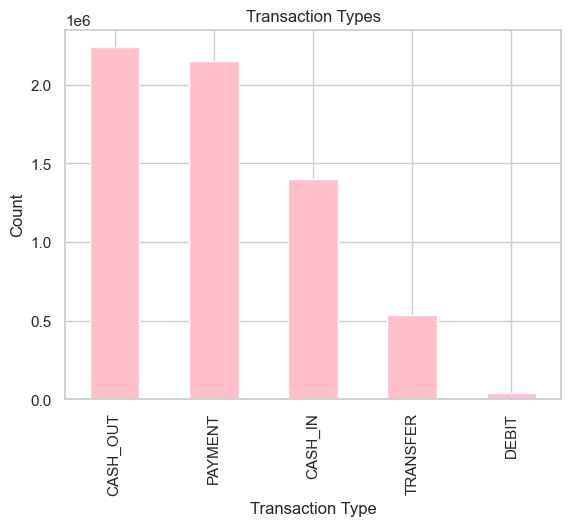

In [12]:
# How many transactions of each type are there?
df["type"].value_counts().plot(kind="bar", title="Transaction Types",color="pink")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

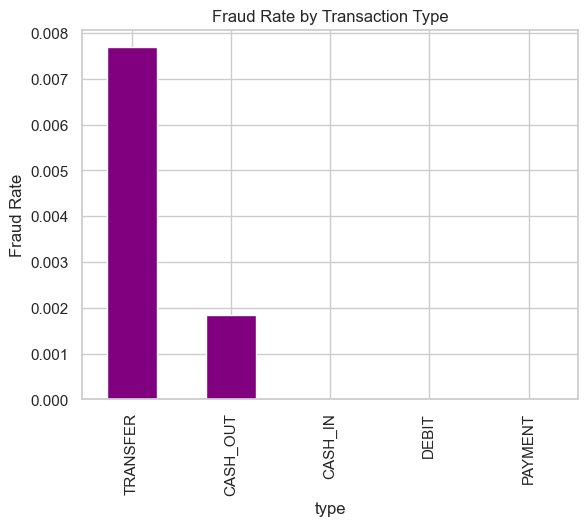

In [13]:
# Fraud rate per transaction type
fraud_by_type = df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar", title="Fraud Rate by Transaction Type", color="purple")
plt.ylabel("Fraud Rate")
plt.show()

### 2.4 Transaction amounts

In [14]:
# Summary statistics of the transaction amount
df["amount"].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

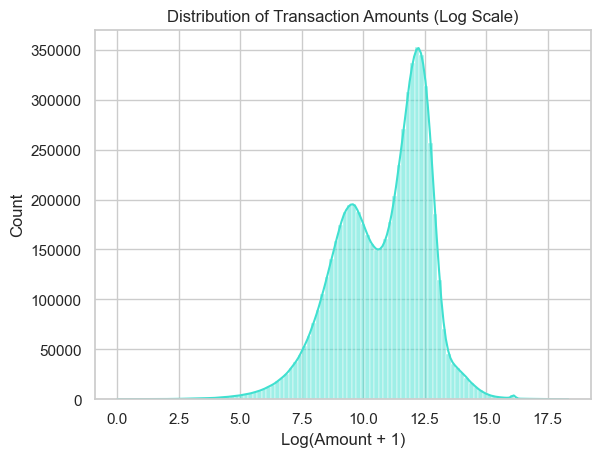

In [15]:
# Amounts are very skewed, so plot them on a log scale
sns.histplot(np.log1p(df["amount"]), bins=100,kde=True, color="turquoise")
plt.title("Distribution of Transaction Amounts (Log Scale)")
plt.xlabel("Log(Amount + 1)")
plt.show()

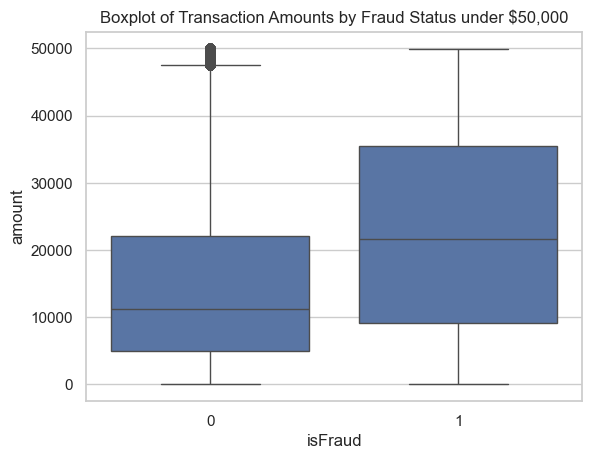

In [16]:
# Compare amounts of fraud vs. legitimate transactions (amounts < 50k)
sns.boxplot(data= df[df["amount"] < 50000], x="isFraud", y="amount")
plt.title("Boxplot of Transaction Amounts by Fraud Status under $50,000")
plt.show()

### 2.5 Balance changes
If the ledger were consistent, the sender's balance would drop and the receiver's would grow by `amount`.
Many rows break this rule — an important hint used for feature engineering in notebook 02.

In [17]:
# Balance change of sender and receiver
# balanceDiffOrig: how much the sender's balance decreased
# balanceDiffDest: how much the receiver's balance increased
df["balanceDiffOrig"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["balanceDiffDest"] = df["newbalanceDest"] - df["oldbalanceDest"]


In [18]:
# Transactions where the sender's balance went UP (unexpected)
(df["balanceDiffOrig"] < 0).sum()

np.int64(1399253)

In [19]:
# Transactions where the receiver's balance went DOWN (unexpected)
(df["balanceDiffDest"] < 0).sum()

np.int64(1238864)

In [20]:
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0


### 2.6 Fraud over time

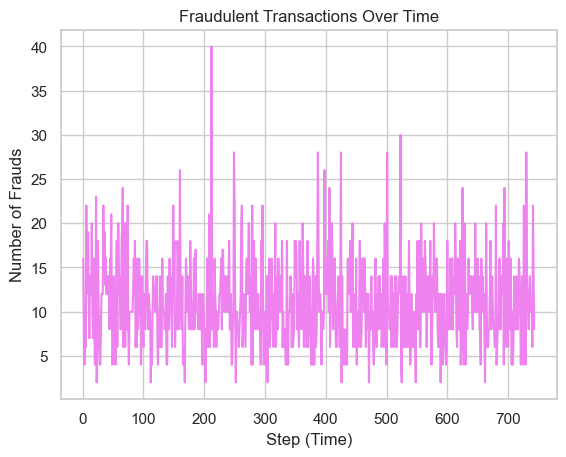

In [21]:
# Number of frauds per time step (1 step = 1 hour of simulation)
fraud_per_step = df[df["isFraud"] == 1]["step"].value_counts().sort_index()
plt.plot(fraud_per_step.index, fraud_per_step.values,label= "Frauds by Step", color="violet")
plt.xlabel("Step (Time)")
plt.ylabel("Number of Frauds")
plt.title("Fraudulent Transactions Over Time")
plt.grid(True)
plt.show()

In [22]:
# The tutorial drops 'step' (time). (Notebook 02 keeps it as hour-of-day.)
df.drop(columns= "step", inplace=True)

In [23]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


### 2.7 Senders & receivers

In [24]:
# Customers sending the most transactions
top_senders = df["nameOrig"].value_counts().head(10)

In [25]:
top_senders

nameOrig
C1902386530    3
C363736674     3
C545315117     3
C724452879     3
C1784010646    3
C1677795071    3
C1462946854    3
C1999539787    3
C2098525306    3
C400299098     3
Name: count, dtype: int64

In [26]:
# Customers receiving the most transactions
top_receivers = df["nameDest"].value_counts().head(10)

In [27]:
top_receivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C451111351      99
C1789550256     99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [28]:
# Do fraudsters reuse the same account? (No - every fraud has a different sender)
fraud_users = df[df["isFraud"] == 1]["nameOrig"].value_counts().head(10)

In [29]:
fraud_users

nameOrig
C1305486145    1
C755286039     1
C973279667     1
C258213312     1
C1640703547    1
C1127265876    1
C317779855     1
C1064034527    1
C1141104763    1
C1966863341    1
Name: count, dtype: int64

### 2.8 Focus on TRANSFER and CASH_OUT

In [30]:
# Fraud only occurs in TRANSFER and CASH_OUT - zoom into those two types
fraud_types = df[df["type"].isin(["TRANSFER", "CASH_OUT"])]

In [31]:
fraud_types["type"].value_counts()  

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

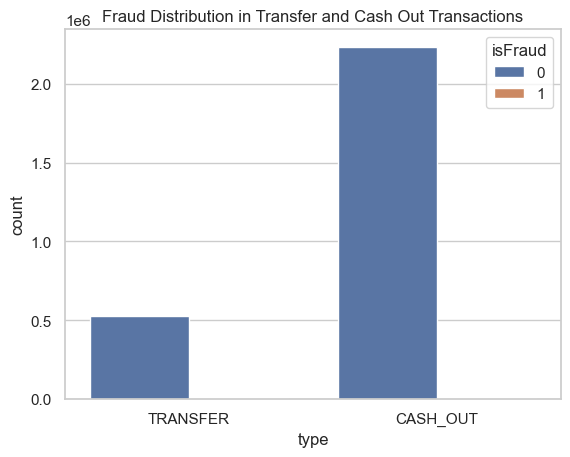

In [32]:
# Fraud vs. legitimate counts within TRANSFER and CASH_OUT
sns.countplot(data=fraud_types, x="type", hue="isFraud")
plt.title("Fraud Distribution in Transfer and Cash Out Transactions")
plt.show()

### 2.9 Correlations

In [33]:
# Correlation between numeric columns and the target
corr = df[["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]].corr()

In [34]:
corr

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


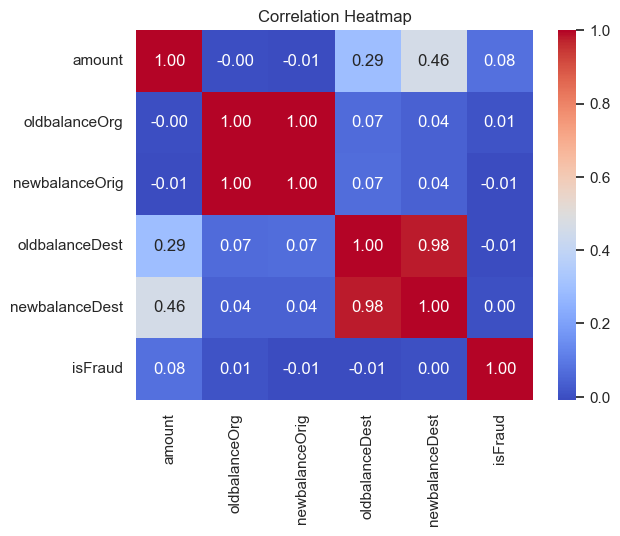

In [35]:
# Visualize the correlation matrix
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

### 2.10 Accounts emptied by a transfer
A classic fraud pattern: the attacker takes over an account and moves **the whole balance** out.

In [36]:
# Typical fraud pattern: account fully emptied by a TRANSFER / CASH_OUT
zero_after_transfer = df[
    (df["oldbalanceOrg"] > 0) & 
    (df["newbalanceOrig"] == 0) & 
    (df["type"].isin(["TRANSFER", "CASH_OUT"]))]

In [37]:
len(zero_after_transfer)

1188074

In [38]:
zero_after_transfer.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
2,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0,181.0,0.00
3,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0,181.0,-21182.00
15,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0,15325.0,46430.44
19,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0,705.0,-22425.00
24,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0,10835.0,2712905.89


In [39]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

## 3. Baseline model — Logistic Regression

- Drop ID-like columns (`nameOrig`, `nameDest`) and `isFlaggedFraud`
- `StandardScaler` for numeric columns, `OneHotEncoder` for `type`
- `LogisticRegression(class_weight="balanced")` to compensate for the class imbalance

In [40]:
# Modelling imports
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [41]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [42]:
# Drop ID columns (no generalizable signal) and the rule-based flag (would leak the old system's decision)
df_model = df.drop(["nameOrig", "nameDest", "isFlaggedFraud"], axis=1)

In [43]:
df_model.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,181.00,0.0
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,181.00,-21182.0
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0


In [44]:
# Columns used by the model
categorical = ["type"]
numeric = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

In [45]:
# Features (X) and target (y)
y = df_model["isFraud"]
X = df_model.drop("isFraud", axis=1)

In [46]:
# 70/30 split. stratify=y keeps the same fraud ratio (0.13%) in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [47]:
# Preprocessing: scale numeric columns, one-hot encode the transaction type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(drop='first'), categorical)
    ],
    remainder = "drop"
)

In [48]:
# Full pipeline: preprocessing + Logistic Regression.
# class_weight='balanced' gives the rare fraud class much more weight
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000))
])

In [49]:
# Train the model (takes a few minutes on 4.4M rows)
pipeline.fit(X_train, y_train)    

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

## 4. Evaluation

In [50]:
# Predict on the unseen test set
y_pred = pipeline.predict(X_test)

In [51]:
# Precision / recall / F1 per class
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1906322
           1       0.02      0.94      0.04      2464

    accuracy                           0.95   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.95      0.97   1908786



In [52]:
# Confusion matrix: [[TN, FP], [FN, TP]]
confusion_matrix(y_test, y_pred)

array([[1804823,  101499],
       [    151,    2313]])

In [53]:
# Accuracy (%) - misleading on imbalanced data, see notebook 02
pipeline.score(X_test, y_test)*100

94.67462565211606

### Result & limitations
- Recall (fraud) **0.94** → most frauds are caught.
- Precision (fraud) **0.02** → ~101k false alarms for ~2.3k real frauds; roughly 44 false alarms per real fraud.
- Accuracy 94.7% looks good but is misleading: predicting "never fraud" already scores 99.87%.

➡️ **[Notebook 02](02_improved_model.ipynb)** improves precision from 0.02 to ~0.94 while keeping recall ≥ 0.95.

## 5. Save the baseline model

In [54]:
# Save the trained baseline pipeline (preprocessing + model) to disk
import joblib
joblib.dump(pipeline, "../models/baseline_logreg_pipeline.pkl")

['../models/baseline_logreg_pipeline.pkl']